In [1]:
import numpy as np
from matplotlib import pyplot as plt
from hw3code import lattice_eigensolution as LE
from hw3code import b,T,T2

In [2]:
Z = 500

Xpath = np.linspace(-b,b,2*Z)
Xpoints = [Xpath[0],Xpath[Z-1],Xpath[-1]]
Knames = [r'$-X$',r'$\Gamma$',r'$X$']

In [3]:

N_odd1 = 13
N_even1 = N_odd1+1
Eodd1,Codd1 = LE(N_odd1,Z,T)
Eeven1,Ceven1 = LE(N_even1,Z,T)

Eodd1b,Codd1b = LE(N_odd1,Z,T2)
Eeven1b,Ceven1b = LE(N_even1,Z,T2)


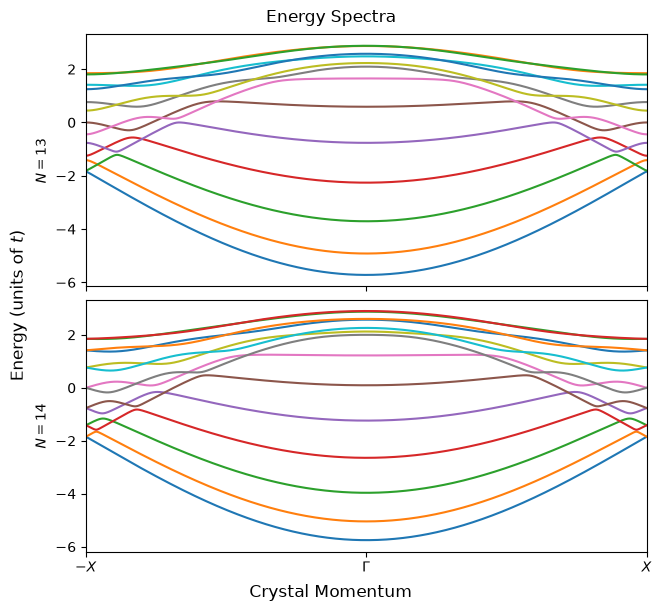

In [4]:
#Plotting, done Hunter's Way

fig, (ax1,ax2) = plt.subplots(2, figsize = (6.5,6),constrained_layout = True)
for E in Eodd1:
    ax1.plot(Xpath,E)

ax1.set_ylabel(f'$N={N_odd1}$');
ax1.set_xlim(Xpoints[0],Xpoints[-1])
ax1.set_xticks(Xpoints,Knames);


for E in Eeven1:
    ax2.plot(Xpath,E)
ax2.sharex(ax1)
ax2.set_ylabel(f'$N={N_even1}$');


ax1.tick_params(labelbottom = False)
fig.suptitle('Energy Spectra');
fig.supylabel(r'Energy (units of $t$)');
fig.supxlabel('Crystal Momentum');
fig.savefig('spectra.pdf', dpi=600)

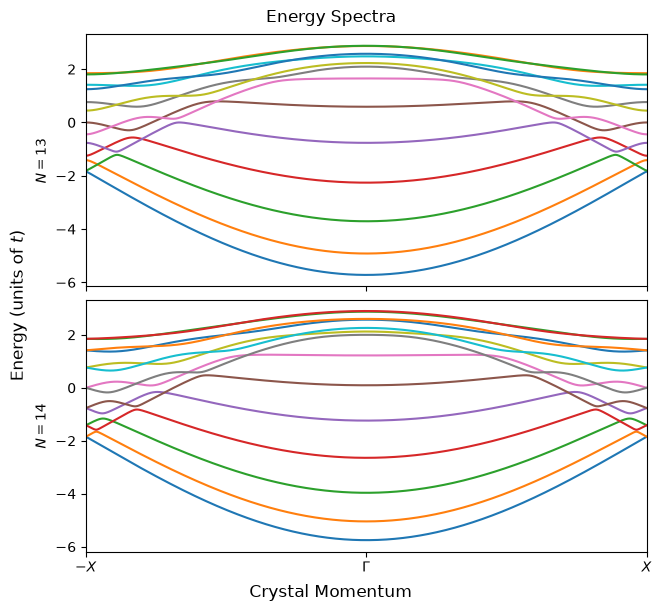

In [5]:
#Plotting Baishali's Way

fig, (ax1,ax2) = plt.subplots(2, figsize = (6.5,6),constrained_layout = True)
for E in Eodd1b:
    ax1.plot(Xpath,E)

ax1.set_ylabel(f'$N={N_odd1}$');
ax1.set_xlim(Xpoints[0],Xpoints[-1])
ax1.set_xticks(Xpoints,Knames);


for E in Eeven1b:
    ax2.plot(Xpath,E)
ax2.sharex(ax1)
ax2.set_ylabel(f'$N={N_even1}$');


ax1.tick_params(labelbottom = False)
fig.suptitle('Energy Spectra');
fig.supylabel(r'Energy (units of $t$)');
fig.supxlabel('Crystal Momentum');
fig.savefig('spectra.pdf', dpi=600)

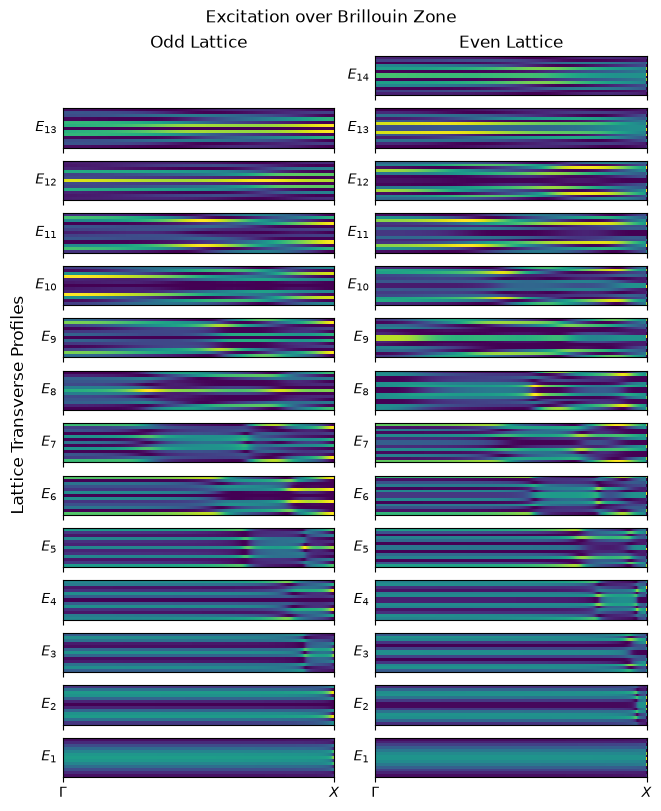

In [6]:
# Hunter's Way

fig, axes = plt.subplots(N_even1,2, sharex = True, figsize = (6.5,8), constrained_layout = True)

Xmesheven, Ymesheven = np.meshgrid(Xpath[Z:],np.arange(N_even1))
Xmeshodd, Ymeshodd = np.meshgrid(Xpath[Z:],np.arange(N_odd1))

for col,Xmesh,Ymesh,C in zip(axes.T,[Xmeshodd,Xmesheven],[Ymeshodd,Ymesheven],[Codd1,Ceven1]):
        for i,ax in enumerate(reversed(col)):
                try:
                        P = abs(C[i,Z:,:].T)**2
                        ax.pcolormesh(Xmesh,Ymesh, P, cmap = 'viridis')
                        ax.set_yticks([])
                        ax.set_ylabel(rf'$E_{{{i+1}}}$', rotation = 0, ha= 'right', va = 'center')
                except:
                        ax.set_axis_off()
axes[0][-1].set_xticks([Xpath[Z-1],Xpath[2*Z-1]],[r'$\Gamma$',r'$X$'])
axes[0][-1].set_xlim(Xpath[Z-1],Xpath[2*Z-1]);


fig.supylabel('Lattice Transverse Profiles');
fig.suptitle('Excitation over Brillouin Zone');
axes[0][0].set_title('Odd Lattice')
axes[0][1].set_title('Even Lattice')

fig.savefig('transverse.pdf', dpi = 600)

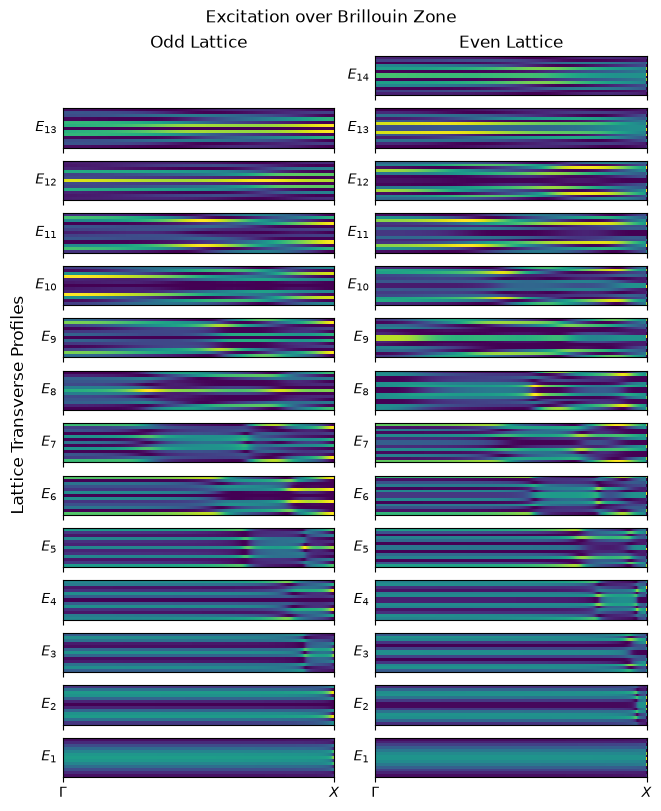

In [7]:
# Baishali's Way
fig, axes = plt.subplots(N_even1,2, sharex = True, figsize = (6.5,8), constrained_layout = True)

Xmesheven, Ymesheven = np.meshgrid(Xpath[Z:],np.arange(N_even1))
Xmeshodd, Ymeshodd = np.meshgrid(Xpath[Z:],np.arange(N_odd1))

for col,Xmesh,Ymesh,C in zip(axes.T,[Xmeshodd,Xmesheven],[Ymeshodd,Ymesheven],[Codd1b,Ceven1b]):
        for i,ax in enumerate(reversed(col)):
                try:
                        P = abs(C[i,Z:,:].T)**2
                        ax.pcolormesh(Xmesh,Ymesh, P, cmap = 'viridis')
                        ax.set_yticks([])
                        ax.set_ylabel(rf'$E_{{{i+1}}}$', rotation = 0, ha= 'right', va = 'center')
                except:
                        ax.set_axis_off()
axes[0][-1].set_xticks([Xpath[Z-1],Xpath[2*Z-1]],[r'$\Gamma$',r'$X$'])
axes[0][-1].set_xlim(Xpath[Z-1],Xpath[2*Z-1]);


fig.supylabel('Lattice Transverse Profiles');
fig.suptitle('Excitation over Brillouin Zone');
axes[0][0].set_title('Odd Lattice')
axes[0][1].set_title('Even Lattice')

fig.savefig('transverse.pdf', dpi = 600)